**Developing a Tiny Transformer Language Model** -10/10/2026

In [42]:
%pip install datasets torch matplotlib tqdm


**Load the dataset**
- Loading only 1,0000 stories initially to make the lab more manageable








In [43]:
from datasets import load_dataset

dataset = load_dataset(
    "roneneldan/TinyStories",
    split="train",
    streaming=True
)

stories = list(dataset.take(10000))

print("Number of stories:", len(stories))

Number of stories: 10000


In [44]:
for i in range(3):
    print(f"\nStory {i+1}:")
    print(stories[i]["text"][:500])
    print("-" * 50)


Story 1:
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them b
--------------------------------------------------

Story 2:
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park when he saw a big tree. The tree had many leaves that were falling. Beep liked how the leaves fall and wanted to play with them. Beep drove under the tree and watched the leaves fall on him. He laugh

Average story length: 867.4761
Shortest story: 205
Longest story: 4540


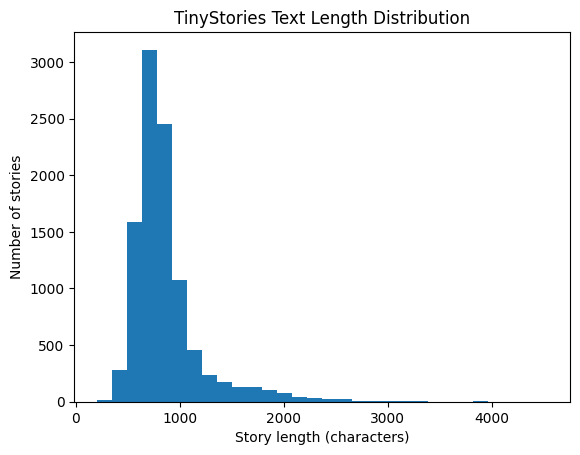

In [45]:
import matplotlib.pyplot as plt

lengths = [len(story["text"]) for story in stories]

print("Average story length:", sum(lengths) / len(lengths))
print("Shortest story:", min(lengths))
print("Longest story:", max(lengths))

plt.hist(lengths, bins=30)
plt.xlabel("Story length (characters)")
plt.ylabel("Number of stories")
plt.title("TinyStories Text Length Distribution")
plt.show()

This creates a histogram showing the distribution of story lengths.

**character level tokenization**



1.   Combine all stories into one text



In [46]:
text = "\n".join(story["text"] for story in stories)

print("Total characters:", len(text))
print("\nSample text:")
print(text[:500])

Total characters: 8684760

Sample text:
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them b



2.  Identify unique characters


In [47]:
chars = sorted(list(set(text)))

vocab_size = len(chars)

print("Unique characters:", chars)
print("Vocabulary size:", vocab_size)

Unique characters: ['\n', ' ', '!', '"', '$', '&', "'", '*', ',', '-', '.', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '¡', '¦', '©', '«', '±', '³', '»', 'Â', 'Ã', 'â', 'œ', '˜', '“', '”', '€', '™']
Vocabulary size: 92


The vocabulary contains every unique character in our dataset, including letters, numbers, spaces, and punctuation.


3. Convert characters into numbers





In [48]:
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)

sample = "Once upon a time"

encoded = encode(sample)

print("Original:", sample)
print("Encoded:", encoded)
print("Decoded:", decode(encoded))

Original: Once upon a time
Encoded: [38, 63, 52, 54, 1, 70, 65, 64, 63, 1, 50, 1, 69, 58, 62, 54]
Decoded: Once upon a time


list of numerical IDs followed by the original text reconstructed from those IDs.

4. Convert the entire dataset into a PyTorch tensor

In [49]:
import torch

data = torch.tensor(encode(text), dtype=torch.long)

print("Dataset shape:", data.shape)
print("First 20 tokens:", data[:20])

Dataset shape: torch.Size([8684760])
First 20 tokens: tensor([38, 63, 54,  1, 53, 50, 74,  8,  1, 50,  1, 61, 58, 69, 69, 61, 54,  1,
        56, 58])


text is represented as numerical tokens

5. Split into training and validation data - 80% Training , 20% Testing

In [50]:
n = int(0.8 * len(data))

train_data = data[:n]
val_data = data[n:]

print("Training tokens:", len(train_data))
print("Validation tokens:", len(val_data))

Training tokens: 6947808
Validation tokens: 1736952


**Preparing Training Data**

1. Set the sequence length and batch size

In [51]:
block_size = 64
batch_size = 32

print("Block size:", block_size)
print("Batch size:", batch_size)

Block size: 64
Batch size: 32


- block_size = 64: The model processes sequences of 64 characters at a time.
- batch_size = 32: The model trains on 32 sequences simultaneously.

2. Create the batch generation function

In [52]:
torch.manual_seed(42)

def get_batch(split):
    source = train_data if split == "train" else val_data

    ix = torch.randint(
        len(source) - block_size,
        (batch_size,)
    )

    x = torch.stack([
        source[i:i + block_size] for i in ix
    ])

    y = torch.stack([
        source[i + 1:i + block_size + 1] for i in ix
    ])

    return x, y

- Selects either training or validation data.
- Randomly chooses 32 starting positions.
- Extracts 64-character input sequences.
- Creates target sequences shifted one character forward.

3. Test the function

In [53]:
xb, yb = get_batch("train")

print("Input shape:", xb.shape)
print("Target shape:", yb.shape)

Input shape: torch.Size([32, 64])
Target shape: torch.Size([32, 64])


This means we have 32 sequences, each containing 64 tokens.

4. Visualize the input and target sequences

In [54]:
print("Input text:")
print(decode(xb[0].tolist()))

print("\nTarget text:")
print(decode(yb[0].tolist()))

Input text:
iped his cheek with her hand. 

The naughty boy was sad, but his

Target text:
ped his cheek with her hand. 

The naughty boy was sad, but his 


**Transformer Architecture**

In [55]:
import torch
import torch.nn as nn
import torch.nn.functional as F



1.   Set the model parameters




In [56]:
n_embd = 128        # Embedding dimension
n_head = 4          # Number of attention heads
n_layer = 2         # Number of Transformer layers
dropout = 0.1       # Dropout probability

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)
print("Vocabulary size:", vocab_size)

Using device: cuda
Vocabulary size: 92



n_embd = 128	         

*   Each token is represented by 128 numbers

n_head = 4

*   Four attention heads learn different relationships

n_layer = 2

*   Two Transformer blocks

dropout = 0.1


*   Helps reduce overfitting

device


*   Uses GPU if available, otherwise CPU



2. Create the masked self attention mechanism - When predicting the next character, the model must not see future characters.

In [58]:
class MultiHeadAttention(nn.Module):

    def __init__(self):
        super().__init__()

        self.attn = nn.MultiheadAttention(
            embed_dim=n_embd,
            num_heads=n_head,
            dropout=dropout,
            batch_first=True
        )

    def forward(self, x):
        T = x.shape[1]

        mask = torch.triu(
            torch.ones(
                T, T,
                device=x.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        out, _ = self.attn(
            x, x, x,
            attn_mask=mask,
            need_weights=False
        )

        return out

3. Create the feed-forward network

In [59]:
class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)

The feed forward network helps the model learn more complex patterns from the attention outputs.

4. Create a Transformer block

In [60]:
class TransformerBlock(nn.Module):
    def __init__(self):
        super().__init__()

        self.attention = MultiHeadAttention()
        self.ffwd = FeedForward()

        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.attention(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))

        return x

5. Build the complete Tiny Transformer

In [61]:
class TinyTransformer(nn.Module):
    def __init__(self):
        super().__init__()

        self.token_embedding = nn.Embedding(
            vocab_size, n_embd
        )

        self.position_embedding = nn.Embedding(
            block_size, n_embd
        )

        self.blocks = nn.Sequential(
            *[TransformerBlock() for _ in range(n_layer)]
        )

        self.ln_f = nn.LayerNorm(n_embd)

        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        token_emb = self.token_embedding(idx)

        positions = torch.arange(
            T, device=idx.device
        )

        pos_emb = self.position_embedding(positions)

        x = token_emb + pos_emb

        x = self.blocks(x)

        x = self.ln_f(x)

        logits = self.lm_head(x)

        loss = None

        if targets is not None:
            B, T, C = logits.shape

            logits_flat = logits.reshape(B * T, C)
            targets_flat = targets.reshape(B * T)

            loss = F.cross_entropy(
                logits_flat, targets_flat
            )

        return logits, loss

6. Test the model architecture

In [62]:
model = TinyTransformer().to(device)

xb, yb = get_batch("train")

xb = xb.to(device)
yb = yb.to(device)

logits, loss = model(xb, yb)

print("Output shape:", logits.shape)
print("Initial loss:", loss.item())

total_params = sum(
    p.numel() for p in model.parameters()
)

print("Total parameters:", total_params)

Output shape: torch.Size([32, 64, 92])
Initial loss: 4.7333984375
Total parameters: 428636


**Initialize the Model**

In [63]:
learning_rate = 3e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate
)

print("Optimizer: AdamW")
print("Learning rate:", learning_rate)
print("Loss function: Cross Entropy")

Optimizer: AdamW
Learning rate: 0.0003
Loss function: Cross Entropy


Configure training settings

In [64]:
max_iters = 500
eval_interval = 100
eval_iters = 20

print("Training iterations:", max_iters)
print("Evaluation interval:", eval_interval)
print("Evaluation batches:", eval_iters)

Training iterations: 500
Evaluation interval: 100
Evaluation batches: 20


Verify the configuration

In [65]:
print("Device:", device)
print("Model parameters:", total_params)
print("Optimizer:", type(optimizer).__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])

Device: cuda
Model parameters: 428636
Optimizer: AdamW
Learning rate: 0.0003


**Train the Transformer Language Model**

Create a function to evaluate loss

In [66]:
@torch.no_grad()
def estimate_loss():
    results = {}

    model.eval()

    for split in ["train", "val"]:
        losses = []

        for _ in range(eval_iters):
            xb, yb = get_batch(split)

            xb = xb.to(device)
            yb = yb.to(device)

            logits, loss = model(xb, yb)

            losses.append(loss.item())

        results[split] = sum(losses) / len(losses)

    model.train()

    return results

Create the training loop

In [67]:
from tqdm.auto import tqdm

train_losses = []
val_losses = []
eval_steps = []

model.train()

for iteration in tqdm(range(max_iters)):

    # Evaluate model periodically
    if iteration % eval_interval == 0 or iteration == max_iters - 1:

        losses = estimate_loss()

        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        eval_steps.append(iteration)

        print(
            f"Step {iteration}: "
            f"Train Loss = {losses['train']:.4f}, "
            f"Validation Loss = {losses['val']:.4f}"
        )

    # Get a training batch
    xb, yb = get_batch("train")

    xb = xb.to(device)
    yb = yb.to(device)

    # Forward propagation
    logits, loss = model(xb, yb)

    # Backpropagation
    optimizer.zero_grad(set_to_none=True)
    loss.backward()

    # Update model parameters
    optimizer.step()

print("Training completed!")

  0%|          | 0/500 [00:00<?, ?it/s]

Step 0: Train Loss = 4.7161, Validation Loss = 4.7183
Step 100: Train Loss = 2.5529, Validation Loss = 2.5759
Step 200: Train Loss = 2.3862, Validation Loss = 2.3990
Step 300: Train Loss = 2.2888, Validation Loss = 2.2854
Step 400: Train Loss = 2.2119, Validation Loss = 2.2078
Step 499: Train Loss = 2.1321, Validation Loss = 2.1324
Training completed!


Plot training and validation loss

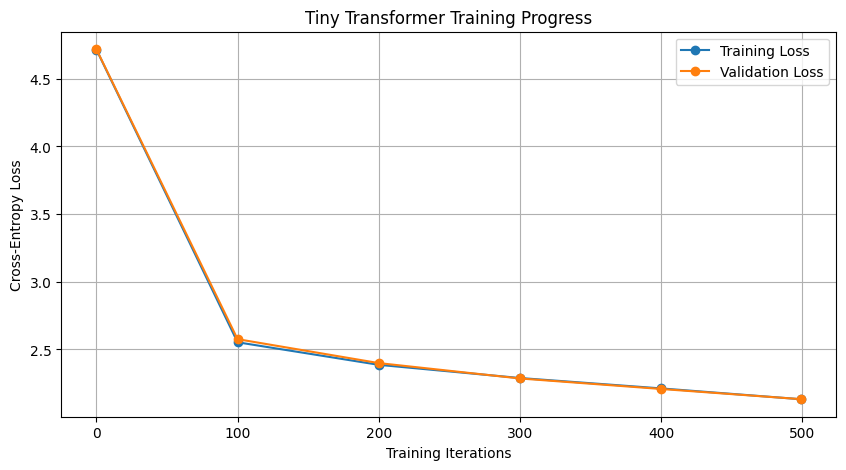

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(eval_steps, train_losses, label="Training Loss", marker="o")
plt.plot(eval_steps, val_losses, label="Validation Loss", marker="o")

plt.xlabel("Training Iterations")
plt.ylabel("Cross-Entropy Loss")
plt.title("Tiny Transformer Training Progress")
plt.legend()
plt.grid(True)
plt.show()


graph comparing training and validation loss.



**Monitor Training**

Display the training results

In [69]:
import pandas as pd

results = pd.DataFrame({
    "Iteration": eval_steps,
    "Training Loss": train_losses,
    "Validation Loss": val_losses
})

print(results.to_string(index=False))

 Iteration  Training Loss  Validation Loss
         0       4.716100         4.718325
       100       2.552917         2.575904
       200       2.386245         2.399019
       300       2.288789         2.285432
       400       2.211931         2.207820
       499       2.132076         2.132419


Check whether the model improved

In [70]:
print("Initial Training Loss:", round(train_losses[0], 4))
print("Final Training Loss:", round(train_losses[-1], 4))

print("Initial Validation Loss:", round(val_losses[0], 4))
print("Final Validation Loss:", round(val_losses[-1], 4))

improvement = (
    (train_losses[0] - train_losses[-1])
    / train_losses[0]
) * 100

print(f"Training Loss Reduction: {improvement:.2f}%")

Initial Training Loss: 4.7161
Final Training Loss: 2.1321
Initial Validation Loss: 4.7183
Final Validation Loss: 2.1324
Training Loss Reduction: 54.79%


Both losses decreased substantially, which indicates the model is learning character patterns and improving its next-character predictions. There is no obvious sign of overfitting from these endpoint results.

**Calculate Perplexity**

In [71]:
import math

losses = estimate_loss()

print("Validation Loss:", round(losses["val"], 4))
print("Perplexity:", round(math.exp(losses["val"]), 4))

Validation Loss: 2.124
Perplexity: 8.3648


**Generate Stories**

In [72]:
@torch.no_grad()
def generate_text(model, prompt, max_new_tokens=300):
    model.eval()

    idx = torch.tensor(
        [encode(prompt)],
        dtype=torch.long,
        device=device
    )

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -block_size:]

        logits, _ = model(idx_cond)

        logits = logits[:, -1, :]

        probs = F.softmax(logits, dim=-1)

        next_token = torch.multinomial(
            probs, num_samples=1
        )

        idx = torch.cat((idx, next_token), dim=1)

    return decode(idx[0].tolist())

Generate your first story

In [85]:
prompt = "Once upon a time"

generated_story = generate_text(
    model,
    prompt,
    max_new_tokens=300
)

print("Generated Story:\n")
import textwrap

print(textwrap.fill(generated_story, width=80))

Generated Story:

Once upon a time tare.  The day, was a said, "Whe said, "Whing said, Lily somy
go the he cried to and got that waluting but and so becotle. They loved the
bught over her ard going and to on the this do good they want juld the fave the
sooke the goon abight free and the joy lanked they. The gre?" toge. Mommy and
She


Train for another 1,000 iterations

In [74]:
model.train()

extra_iters = 1000

for iteration in range(extra_iters):

    xb, yb = get_batch("train")
    xb, yb = xb.to(device), yb.to(device)

    logits, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if (iteration + 1) % 200 == 0:
        print(
            f"Extra Step {iteration + 1}: "
            f"Loss = {loss.item():.4f}"
        )

Extra Step 200: Loss = 2.0226
Extra Step 400: Loss = 1.9540
Extra Step 600: Loss = 1.8741
Extra Step 800: Loss = 1.7445
Extra Step 1000: Loss = 1.6779


Evaluate the Model After Additional Training

In [84]:
final_losses = estimate_loss()

print("Total Training Iterations:", max_iters + extra_iters)

print("Final Training Loss:",
      round(final_losses["train"], 4))

print("Final Validation Loss:",
      round(final_losses["val"], 4))

print("Final Perplexity:",
      round(math.exp(final_losses["val"]), 4))

Total Training Iterations: 1500
Final Training Loss: 1.6417
Final Validation Loss: 1.6421
Final Perplexity: 5.1659


Generate another story

In [75]:
new_story = generate_text(
    model,
    "Once upon a time",
    max_new_tokens=300
)

print(new_story)

Once upon a time traulk isped and kint. 

Sam heb king ifur! Tim usterees to was extime, You a out this sralone would to gore veryincelonn's to loogethe toy. He the live. 

They-mex thuch hey asqurseame tooks parted cout. It she someare. They worn the cry,. The of looked the delight bhest crave the were was and and


Experiment with temperature

In [76]:
@torch.no_grad()
def generate_text(model, prompt, max_new_tokens=300, temperature=0.7):
    model.eval()

    idx = torch.tensor(
        [encode(prompt)],
        dtype=torch.long,
        device=device
    )

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -block_size:]

        logits, _ = model(idx_cond)
        logits = logits[:, -1, :] / temperature

        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)

        idx = torch.cat((idx, next_token), dim=1)

    return decode(idx[0].tolist())

In [77]:
print(generate_text(
    model,
    "Once upon a time",
    max_new_tokens=300,
    temperature=0.7
))

Once upon a time fare. He looked a do lund nit was named the more was so frone. The was awas so friend cared to that they go jun the read a said and the she some the pur.

Tom and wasked on the was a sto pand beothe the leack. Timmy to the go they nee bage. They cared it of excited the was and and the plonery sain 


Create and train a three-layer model



In [86]:
# Save original settings
original_n_layer = n_layer

# Change number of Transformer layers
n_layer = 3

# Initialize new model
model_3layers = TinyTransformer().to(device)

optimizer_3layers = torch.optim.AdamW(
    model_3layers.parameters(),
    lr=learning_rate
)

print("New model layers:", n_layer)
print("Parameters:", sum(p.numel() for p in model_3layers.parameters()))

# Train new model
model_3layers.train()

for step in range(500):
    xb, yb = get_batch("train")
    xb, yb = xb.to(device), yb.to(device)

    logits, loss = model_3layers(xb, yb)

    optimizer_3layers.zero_grad(set_to_none=True)
    loss.backward()
    optimizer_3layers.step()

    if (step + 1) % 100 == 0:
        print(f"Step {step+1}, Loss: {loss.item():.4f}")

# Evaluate using 20 validation batches

model_3layers.eval()

validation_losses = []

with torch.no_grad():
    for _ in range(eval_iters):

        xb, yb = get_batch("val")
        xb, yb = xb.to(device), yb.to(device)

        _, loss = model_3layers(xb, yb)

        validation_losses.append(loss.item())

val_loss_3layers = (
    sum(validation_losses) / len(validation_losses)
)

print("3-layer validation loss:",
      round(val_loss_3layers, 4))

print("3-layer perplexity:",
      round(math.exp(val_loss_3layers), 4))

# Restore original setting
n_layer = original_n_layer

New model layers: 3
Parameters: 626908
Step 100, Loss: 2.4978
Step 200, Loss: 2.3955
Step 300, Loss: 2.2948
Step 400, Loss: 2.2010
Step 500, Loss: 2.0894
3-layer validation loss: 2.0921
3-layer perplexity: 8.1021


Compare Two Layer and Three Layer Models

In [87]:
comparison = pd.DataFrame({
    "Model": ["2 Layers", "3 Layers"],
    "Training Iterations": [500, 500],
    "Parameters": [
        total_params,
        sum(p.numel() for p in model_3layers.parameters())
    ],
    "Validation Loss": [
        losses["val"],
        val_loss_3layers
    ],
    "Perplexity": [
        math.exp(losses["val"]),
        math.exp(val_loss_3layers)
    ]
})

print(comparison.to_string(index=False))

   Model  Training Iterations  Parameters  Validation Loss  Perplexity
2 Layers                  500      428636         2.124037    8.364839
3 Layers                  500      626908         2.092121    8.102085


In [89]:
print("Three-Layer Model Generated Story:\n")

generated_story_3layers = generate_text(
    model_3layers,
    "Once upon a time",
    max_new_tokens=300,
    temperature=0.7
)

print(textwrap.fill(generated_story_3layers, width=80))

Three-Layer Model Generated Story:

Once upon a time ing the the was abor and. He the to he thelerse the pe wad to a
ncked so they wad ay was as alof to shenen aitere her and mom, the dout his ache
she kimy tove dand dom a she as. The and She sad loun the fit andaile is ald are
to she ha stald pous tommere hery itlid she lind ge was art herted her s


Save the Trained Model

In [79]:
torch.save({
    "model_state_dict": model.state_dict(),
    "vocab_size": vocab_size,
    "block_size": block_size,
    "n_embd": n_embd,
    "n_head": n_head,
    "n_layer": original_n_layer,
    "dropout": dropout,
    "chars": chars,
    "training_iterations": 1500
}, "tiny_transformer_model.pth")

print("Model saved successfully!")

Model saved successfully!


In [90]:
from google.colab import files

files.download("tiny_transformer_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Create a Gradio Chatbot **

In [80]:
!pip install -q gradio

In [81]:
import gradio as gr

Create the chatbot function

In [82]:
def chatbot(message, history):
    if not message.strip():
        return "Please enter a story prompt."

    try:
        response = generate_text(
            model,
            message,
            max_new_tokens=200,
            temperature=0.7
        )
        return response

    except KeyError:
        return (
            "Your prompt contains characters that are "
            "not in the model's vocabulary. "
            "Please try simple English text."
        )

Gradio interface

In [83]:
demo = gr.ChatInterface(
    fn=chatbot,
    title="Tiny Transformer Story Generator",
    description="Generate short stories using my custom Transformer model.",
    examples=[
        "Once upon a time",
        "There was a little girl",
        "One sunny day",
        "The little dog"
    ]
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0c49c6ab5765e1a1dd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


The model generated some recognizable English words, but the stories were not grammatically correct or fully meaningful. Possible reasons include limited training data, model capacity, context size, and training iterations.

I used 10,000 stories, two Transformer layers, four attention heads, an embedding size of 128, and a context size of 64 characters. I also experimented with a 3 layer Transformer model to observe the effect of increasing model capacity.

To improve the quality of generated stories, I could increase the dataset size, Transformer layers, embedding size, context size, and training iterations. Additionally, cleaning the dataset and using subword tokenization instead of character level tokenization could improve performance. With sufficient training data and computational resources, these improvements may help the model generate more meaningful and coherent stories.